# Fraunhofer Diffraction -- Rectangular Aperture

> Part of *PHYS 0241: Biomedical Imaging* (Prof. Michael E. Durst, Middlebury College). The [textbook page for this notebook](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/python/ch04/ch04-08.html) shows the rendered version together with the pre-rendered animations (course password required).
>
> **Start here:** run the setup cell below first. In Google Colab, choose **File > Save a copy in Drive** to keep your changes.
>
> *Provided for academic use in PHYS 0241; please do not repost or redistribute ([terms of use](https://github.com/durstme/textbook-biomedicalimaging-notebooks/blob/main/LICENSE.md)).*

In [ ]:
# --- Setup: run this cell first.  It does nothing outside Google Colab. ---
import sys, os, importlib.util, urllib.request
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    # interactive matplotlib (%matplotlib widget) needs ipympl and Colab's custom widget manager
    if importlib.util.find_spec("ipympl") is None:
        get_ipython().run_line_magic("pip", "install -q ipympl")
        importlib.invalidate_caches()  # make the freshly installed package importable
        try:  # matplotlib caches its backend list on first use; refresh it so no restart is needed
            from matplotlib.backends.registry import backend_registry
            backend_registry._clear()
        except Exception:
            pass
    import ipympl  # noqa: F401
    from google.colab import output
    output.enable_custom_widget_manager()
    print("Colab setup done. If a %matplotlib widget cell still errors, use Runtime > Restart session, then Run all.")

## Import libraries

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, PowerNorm, LogNorm
from matplotlib import cm
from matplotlib.colors import LightSource
from mpl_toolkits.mplot3d import Axes3D

In [2]:
%matplotlib inline
# Define global "bold" style parameters
# This restores the thicker lines and fonts seen in older versions
plot_params = {
    # --- Fonts ---
    'font.size': 18,
    'font.family': 'sans-serif',
    
    # --- Axes (The Box) ---
    'axes.linewidth': 1.0,       # Thicker box around the plot
    
    # --- Lines (The Signal) ---
    'lines.linewidth': 2.5,      # Thicker default plot lines
}

# Apply these settings globally
plt.rcParams.update(plot_params)

## Define parameters

In [3]:

# --- Parameters ---
L1 = 2 * 10**6       # Distance to screen in microns
wavelength1 = 0.632  # Wavelength in microns
ax1 = 40             # slit width in x in microns
ay1 = 40             # slit width in y in microns

# --- Data Generation (High Resolution for Images) ---
N_high = 512
x_ap = np.linspace(-400, 400, N_high)
y_ap = x_ap
X_ap, Y_ap = np.meshgrid(x_ap, y_ap)

# Aperture Function
aperture_2d = np.where((np.abs(X_ap) <= ax1/2) & (np.abs(Y_ap) <= ay1/2), 1.0, 0.0)

# Diffraction Data
x_scr = np.linspace(-1e5, 1e5, N_high)
y_scr = x_scr
X_scr, Y_scr = np.meshgrid(x_scr, y_scr)

# Diffraction Calculation (Sinc^2)
val_x = (np.pi * ax1 * X_scr) / (wavelength1 * np.sqrt(X_scr**2 + Y_scr**2 + L1**2))
val_y = (np.pi * ay1 * Y_scr) / (wavelength1 * np.sqrt(X_scr**2 + Y_scr**2 + L1**2))
intensity_2d = (np.sinc(val_x/np.pi) * np.sinc(val_y/np.pi))**2

# --- Optimization: Downsampling for 3D Plots ---
stride = 8 
X_ap_3d = X_ap[::stride, ::stride]
Y_ap_3d = Y_ap[::stride, ::stride]
Z_ap_3d = aperture_2d[::stride, ::stride]

X_scr_3d = X_scr[::stride, ::stride]
Y_scr_3d = Y_scr[::stride, ::stride]
Z_scr_3d = intensity_2d[::stride, ::stride]


## Plot

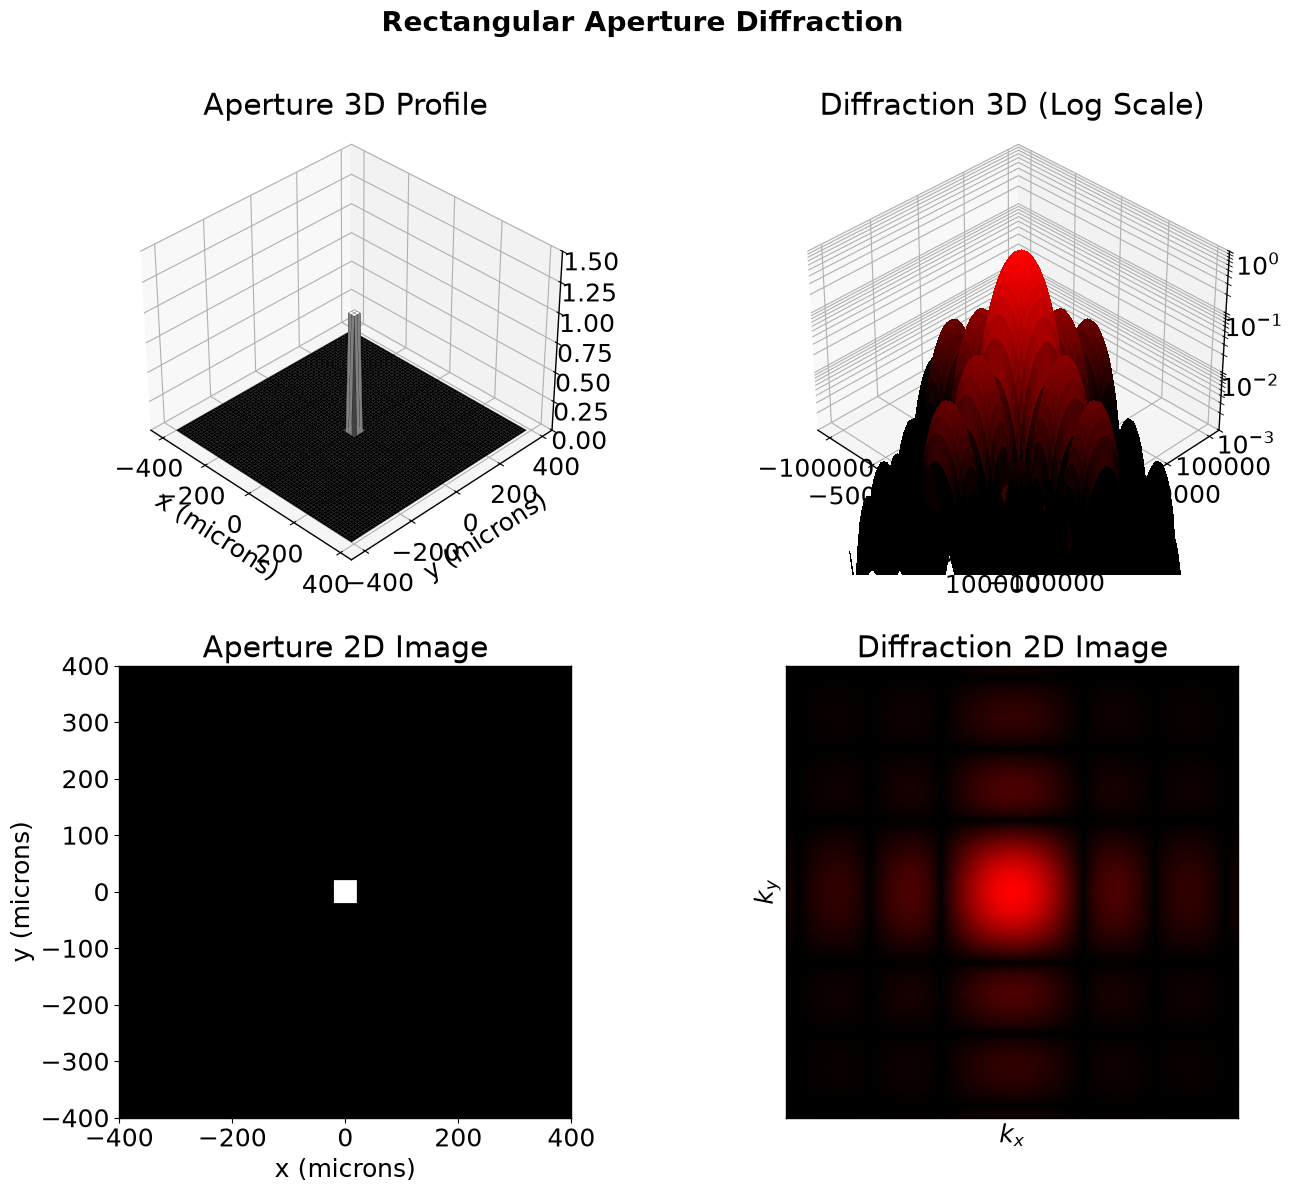

In [4]:

# --- Plotting ---
fig1 = plt.figure(figsize=(14, 12))
fig1.suptitle("Rectangular Aperture Diffraction", fontsize=20, fontweight='bold', y=1.0)

# -------------------------------
# Column 1: Aperture
# -------------------------------

# [1,1] Top Left: Aperture 3D
ax5 = fig1.add_subplot(2, 2, 1, projection='3d')
ls = LightSource(azdeg=315, altdeg=45)

# CHANGED: Replaced solid 'color' with 'cmap=cm.coolwarm'
# The Z-values (Z_ap_3d) now determine the color.
ax5.plot_surface(X_ap_3d, Y_ap_3d, Z_ap_3d, 
                 rstride=1, cstride=1, 
                 cmap='gray', vmin=0, vmax=1,  # black=0, white=1
                 edgecolor='k', linewidth=0.1,      # Thinner black lines for edge definition
                 shade=True, lightsource=ls, antialiased=True)

ax5.set_title("Aperture 3D Profile")
ax5.set_xlabel("x (microns)")
ax5.set_ylabel("y (microns)")
ax5.set_zlim(0, 1.5)
ax5.view_init(elev=35, azim=-45)

# [2,1] Bottom Left: Aperture 2D
ax2 = fig1.add_subplot(2, 2, 3)
ax2.imshow(aperture_2d, extent=[-400, 400, -400, 400], aspect='equal', cmap='gray', vmin=0, vmax=1)
ax2.set_title("Aperture 2D Image")
ax2.set_xlabel("x (microns)")
ax2.set_ylabel("y (microns)")

# -------------------------------
# Column 2: Diffraction Pattern
# -------------------------------

# [1,2] Top Right: Diffraction 3D (Log Scale)
ax3 = fig1.add_subplot(2, 2, 2, projection='3d')
colors = [(0, 0, 0), (1, 0, 0)] 
laser_cmap = LinearSegmentedColormap.from_list("laser_red", colors)
Z_scr_3d_log = Z_scr_3d + 1e-6

surf = ax3.plot_surface(X_scr_3d, Y_scr_3d, Z_scr_3d_log, 
                        rstride=1, cstride=1, 
                        cmap=laser_cmap,
                        norm=LogNorm(vmin=1e-3, vmax=1.0),
                        linewidth=0, antialiased=False)

ax3.set_title("Diffraction 3D (Log Scale)")
ax3.set_xlabel(r"$k_x$")
ax3.set_ylabel(r"$k_y$")
ax3.set_zscale('log') 
ax3.set_zlim(1e-3, 1)
ax3.view_init(elev=35, azim=-45)

# [2,2] Bottom Right: Diffraction 2D
ax4 = fig1.add_subplot(2, 2, 4)
ax4.imshow(intensity_2d, extent=[-1e5, 1e5, -1e5, 1e5], aspect='equal', 
           cmap=laser_cmap, norm=PowerNorm(gamma=0.4))
ax4.set_title("Diffraction 2D Image")
ax4.set_xlabel(r"$k_x$")
ax4.set_ylabel(r"$k_y$")
ax4.set_yticks([]) 
ax4.set_xticks([])

plt.tight_layout()
plt.subplots_adjust(wspace=0.1, hspace=0.2)
plt.show()

## Animation

In [5]:
%matplotlib widget
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, PowerNorm, LogNorm
from matplotlib import cm
from mpl_toolkits.mplot3d import Axes3D
import ipywidgets as widgets
from IPython.display import display

# --- 1. Global Configuration ---
plot_params2 = {
    'font.size': 10,
    'font.family': 'sans-serif',
    'axes.linewidth': 1.0,
}
plt.rcParams.update(plot_params2)

# Constants
L2 = 2 * 10**6       # Screen distance (microns)
lim_ap = 400         # Aperture axis limit
lim_scr = 1e5        # Screen axis limit
N_HIGH = 400         # Resolution for 2D images (High quality)
STRIDE = 10          # Downsampling factor for 3D plots (Speed)

# Coordinate Arrays (High Res)
x_ap2 = np.linspace(-lim_ap, lim_ap, N_HIGH)
y_ap2 = x_ap2
X_ap2, Y_ap2 = np.meshgrid(x_ap2, y_ap2)

x_scr2 = np.linspace(-lim_scr, lim_scr, N_HIGH)
y_scr2 = x_scr2
X_scr2, Y_scr2 = np.meshgrid(x_scr2, y_scr2)

# Coordinate Arrays (Low Res for 3D)
X_ap_3d2 = X_ap2[::STRIDE, ::STRIDE]
Y_ap_3d2 = Y_ap2[::STRIDE, ::STRIDE]
X_scr_3d2 = X_scr2[::STRIDE, ::STRIDE]
Y_scr_3d2 = Y_scr2[::STRIDE, ::STRIDE]

# --- 2. Figure Setup ---
# figsize=(10, 9) is roughly 800-900px wide on most displays
fig = plt.figure(figsize=(10, 9))
fig.canvas.header_visible = False
fig.canvas.footer_visible = False
fig.suptitle("Rectangular Aperture Diffraction", fontsize=16, fontweight='bold')

# [1,1] Top Left: Aperture 3D
ax6 = fig.add_subplot(2, 2, 1, projection='3d')
ax6.set_title("Aperture 3D")
ax6.set_zlim(0, 1.2)
ax6.set_xticks([]); ax6.set_yticks([]); ax6.set_zticks([])
ax6.view_init(elev=35, azim=-45)

# [2,1] Bottom Left: Aperture 2D
ax7 = fig.add_subplot(2, 2, 3)
img_ap = ax7.imshow(np.zeros((N_HIGH, N_HIGH)), extent=[-lim_ap, lim_ap, -lim_ap, lim_ap], 
                    origin='lower', cmap='gray', vmin=0, vmax=1)
ax7.set_title("Aperture 2D")
ax7.set_xlabel("x ($\mu m$)"); ax7.set_ylabel("y ($\mu m$)")

# [1,2] Top Right: Diffraction 3D
ax8 = fig.add_subplot(2, 2, 2, projection='3d')
ax8.set_title("Diffraction 3D (Log Scale)")
ax8.set_zscale('log')
ax8.set_zlim(1e-3, 1)
ax8.set_xticks([]); ax8.set_yticks([]); ax8.set_zticks([])
ax8.view_init(elev=35, azim=-45)

# [2,2] Bottom Right: Diffraction 2D
ax9 = fig.add_subplot(2, 2, 4)
colors2 = [(0, 0, 0), (1, 0, 0)] 
laser_cmap2 = LinearSegmentedColormap.from_list("laser_red", colors2)
img_diff = ax9.imshow(np.zeros((N_HIGH, N_HIGH)), extent=[-lim_scr, lim_scr, -lim_scr, lim_scr], 
                      origin='lower', cmap=laser_cmap2, norm=PowerNorm(gamma=0.4, vmin=0, vmax=1))
ax9.set_title("Diffraction Pattern")
ax9.set_xlabel(r"$k_x$"); ax9.set_ylabel(r"$k_y$")
ax9.set_xticks([]); ax9.set_yticks([])

plt.tight_layout()

# Global variables to hold the 3D surface objects
surf_ap_ref = None
surf_diff_ref = None

# --- 3. Update Logic ---
def update_simulation(ax_val, ay_val, wav_val):
    global surf_ap_ref, surf_diff_ref
    
    # --- A. Calculations ---
    # 1. Aperture
    mask_x = np.abs(X_ap2) <= ax_val/2
    mask_y = np.abs(Y_ap2) <= ay_val/2
    aperture_data = (mask_x & mask_y).astype(float)
    
    mask_x_3d = np.abs(X_ap_3d2) <= ax_val/2
    mask_y_3d = np.abs(Y_ap_3d2) <= ay_val/2
    aperture_3d_data = (mask_x_3d & mask_y_3d).astype(float)

    # 2. Diffraction (Sinc^2 * Sinc^2)
    hyp = np.sqrt(X_scr2**2 + Y_scr2**2 + L2**2)
    beta_x = (ax_val * X_scr2) / (wav_val * hyp) 
    beta_y = (ay_val * Y_scr2) / (wav_val * hyp)
    intensity = (np.sinc(beta_x) * np.sinc(beta_y))**2
    
    hyp_3d = np.sqrt(X_scr_3d2**2 + Y_scr_3d2**2 + L2**2)
    beta_x_3d = (ax_val * X_scr_3d2) / (wav_val * hyp_3d)
    beta_y_3d = (ay_val * Y_scr_3d2) / (wav_val * hyp_3d)
    intensity_3d = (np.sinc(beta_x_3d) * np.sinc(beta_y_3d))**2
    
    # --- B. Update Plots ---
    # Update Images
    img_ap.set_data(aperture_data)
    img_diff.set_data(intensity)
    
    # Update Surfaces
    if surf_ap_ref is not None: surf_ap_ref.remove()
    if surf_diff_ref is not None: surf_diff_ref.remove()
        
    surf_ap_ref = ax6.plot_surface(X_ap_3d2, Y_ap_3d2, aperture_3d_data, 
                                   cmap='gray', vmin=0, vmax=1,
                                   rstride=1, cstride=1, linewidth=0, antialiased=False, shade=True)
    
    surf_diff_ref = ax8.plot_surface(X_scr_3d2, Y_scr_3d2, intensity_3d + 1e-6,
                                     cmap=laser_cmap2, norm=LogNorm(vmin=1e-3, vmax=1),
                                     rstride=1, cstride=1, linewidth=0, antialiased=False)

    fig.canvas.draw_idle()

# --- 4. Controls ---
style = {'description_width': 'initial'}

# MATCHING WIDTH: 800px matches the visual width of a figsize=(10,9) plot nicely
layout = widgets.Layout(width='800px') 

s_ax = widgets.FloatSlider(value=40, min=10, max=100, step=2, description='Width X (um)', style=style, layout=layout)
s_ay = widgets.FloatSlider(value=40, min=10, max=100, step=2, description='Width Y (um)', style=style, layout=layout)
s_wav = widgets.FloatSlider(value=0.632, min=0.400, max=0.800, step=0.01, description='Wavelength (um)', style=style, layout=layout)

def on_change(change):
    update_simulation(s_ax.value, s_ay.value, s_wav.value)

s_ax.observe(on_change, names='value')
s_ay.observe(on_change, names='value')
s_wav.observe(on_change, names='value')

# Initialize
update_simulation(40, 40, 0.632)

display(widgets.VBox([s_ax, s_ay, s_wav]))
plt.show()

### Display animation with javascript from standalone html
[Link to animation](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/animations/ch04/ch04-08_animation.html)

*Animation.* The pre-rendered animation for this section is shown on the [textbook page for this notebook](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/python/ch04/ch04-08.html) (direct link: [ch04-08_animation.html](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/animations/ch04/ch04-08_animation.html)). It is not embedded here because Colab cannot load files from the textbook site; running the code above produces the live version.